In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import lime
import lime.lime_tabular
from lime import submodular_pick
import time
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import LabelEncoder # For transforming categories to integer labels
# Correção de compatibilidade: o LIME usa um import que o IPython 9 removeu
import IPython.core.display as _ipcd
from IPython.display import display, HTML
_ipcd.display = display
_ipcd.HTML = HTML

np.random.seed(123)

# Loading the data


In [2]:
# We will read the training data
data = pd.read_csv('dataset/titanic.csv')

data.replace('?',np.nan, inplace=True)

# Dropping all irrelevant columns
data.drop(columns=['PassengerId', 'Name', 'Cabin', 'Ticket'], inplace = True)

data.dropna(inplace=True)

# Ensuring that Age and Fare is of type float after replacing ? with np.Nan
data['Age'] = data['Age'].astype('float')
data['Fare'] = data['Fare'].astype('float')

# Label Encoding features  Sex fica 0 = female e 1 = male.
categorical_feat = ['Sex']

# Using label encoder to transform string categories to integer labels
le = LabelEncoder()
for feat in categorical_feat:
    data[feat] = le.fit_transform(data[feat]).astype('int')

# One-Hot Encoding Categorical features
data = pd.get_dummies(data, columns=['Embarked'])

In [3]:
features = data.drop(columns=['Survived'])
labels = data['Survived']
# Dividing the data into training-test set with 80:20 split ratio
x_train,x_test,y_train,y_test = train_test_split(features,labels,test_size=0.2, random_state=123)

In [4]:
model = XGBClassifier(n_estimators = 300, random_state = 123)
model.fit(x_train, y_train)
model.score(x_test, y_test)

0.7655502392344498

In [5]:
predict_fn = lambda x: model.predict_proba(x)

# Lime

In [30]:
def make_explainer(seed=123, discretize=True, **kwargs):
    return lime.lime_tabular.LimeTabularExplainer(
        x_train.astype(float).values,
        mode='classification',
        class_names=['Did not Survive', 'Survived'],
        training_labels=y_train.values,
        feature_names=list(features.columns),
        discretize_continuous=discretize,
        random_state=seed,
        **kwargs)

explainer = make_explainer()  # o explainer "normal", usado nos pontos 1, 2 e 5

In [8]:
def show_lime(exp):
    html = exp.as_html(show_table=True)
    display(HTML(f'<div style="background:white; color:black; padding:10px">{html}</div>'))


# 1 · Comparar passageiros

In [9]:
feature_names = list(features.columns)

def explain_passenger(i, explainer=explainer, num_features=5):
    x = x_test.iloc[i].astype(float).values
    exp = explainer.explain_instance(x, predict_fn, num_features=num_features)
    top3 = exp.as_list()[:3]
    row = {
        'Passenger': x_test.index[i],
        'Real': y_test.iloc[i],
        'P(Survived)': round(predict_fn(x.reshape(1, -1))[0, 1], 3),
        'Top 3 conditions (weights)': '; '.join(f'{c} ({w:+.3f})' for c, w in top3),
        'Intercept': round(exp.intercept[1], 3),
        'Local prediction': round(exp.local_pred[0], 3),
        'R2': round(exp.score, 3),   # vai dar jeito no ponto 2
    }
    return exp, row

In [10]:
def show_many(exps, table):
    for exp, (_, row) in zip(exps, table.iterrows()):
        real = 'Survived' if row['Real'] == 1 else 'Did not survive'
        display(HTML(
            f"<h4>Passageiro {row['Passenger']} — real: {real} | "
            f"P(Survived) = {row['P(Survived)']} | local pred = {row['Local prediction']} | "
            f"R² = {row['R2']}</h4>"))
        show_lime(exp)


In [11]:
def passenger_values(pid):
    v = x_test.loc[pid]
    sex = 'F' if v['Sex'] == 0 else 'M'
    emb = next(c.split('_')[1] for c in ['Embarked_C', 'Embarked_Q', 'Embarked_S'] if v[c])
    return (f"Sex={sex}  Age={v['Age']:.0f}  Pclass={v['Pclass']:.0f}  Fare={v['Fare']:.1f}\n"
            f"SibSp={v['SibSp']:.0f}  Parch={v['Parch']:.0f}  Embarked={emb}")

def plot_grid(exps, table, ncols=4):
    nrows = int(np.ceil(len(exps) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.8 * nrows))
    for ax, exp, (_, row) in zip(axes.flat, exps, table.iterrows()):
        conds, weights = zip(*exp.as_list(label=1)[::-1])
        ax.barh(conds, weights, color=['tab:green' if w > 0 else 'tab:red' for w in weights])
        ax.axvline(0, color='grey', lw=0.8)
        ax.set_title(f"#{row['Passenger']}  P={row['P(Survived)']}  real={row['Real']}\n"
                     f"{passenger_values(row['Passenger'])}", fontsize=9)
        ax.tick_params(labelsize=8)
    for ax in axes.flat[len(exps):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


,Passenger,Real,P(Survived),Top 3 conditions (weights),Intercept,Local prediction,R2
0,359,1,1.000,0.00 < Sex <= 1.00 (-0.495); Age <= 21.00 (+0.132); Embarked_C <= 0.00 (-0.107),0.745,0.285,0.396
1,268,0,0.877,0.00 < Sex <= 1.00 (-0.495); Pclass <= 1.00 (+0.242); Embarked_C <= 0.00 (-0.111),0.673,0.348,0.435
2,591,1,0.995,Sex <= 0.00 (+0.494); Age <= 21.00 (+0.124); 1.00 < Pclass <= 2.00 (+0.107),0.236,0.795,0.388
3,990,0,0.126,0.00 < Sex <= 1.00 (-0.486); 2.00 < Pclass <= 3.00 (-0.235); Fare <= 8.05 (+0.120),0.807,0.172,0.457
4,684,0,0.364,Sex <= 0.00 (+0.471); 2.00 < Pclass <= 3.00 (-0.259); Embarked_C <= 0.00 (-0.128),0.492,0.418,0.455


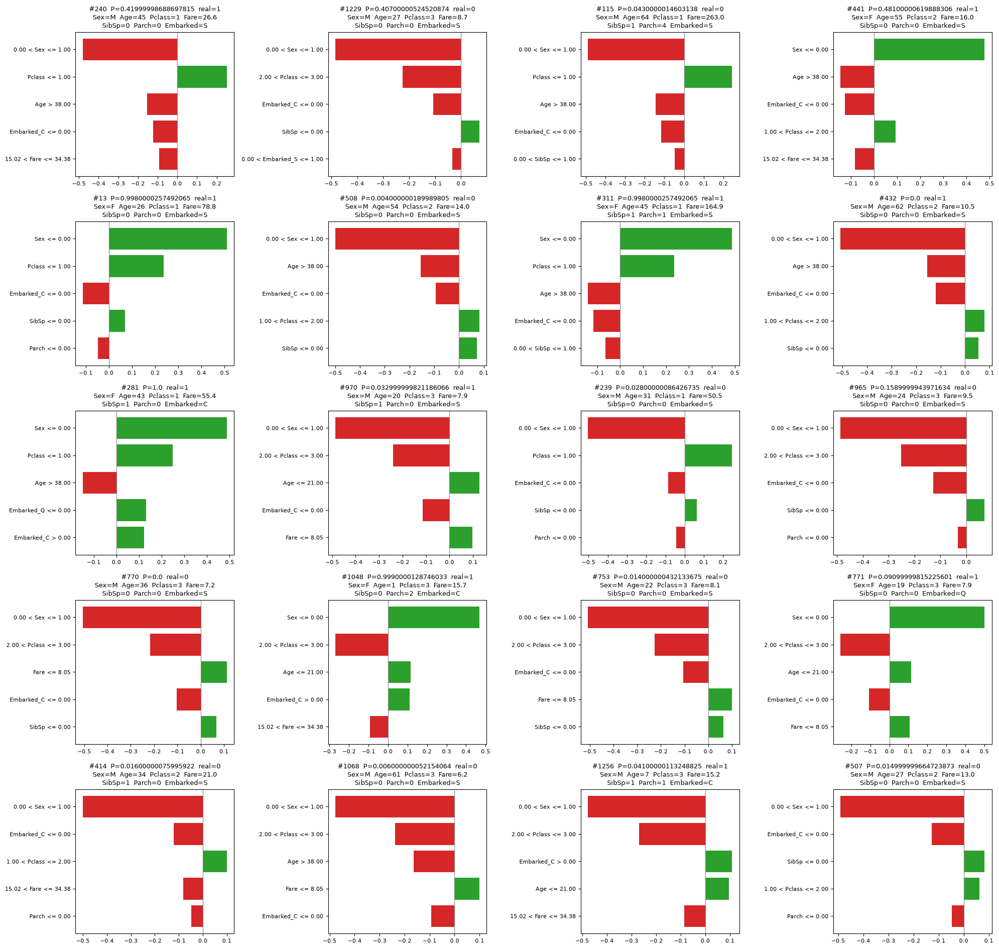

,Passenger,Real,P(Survived),Top 3 conditions (weights),Intercept,Local prediction,R2
5,240,1,0.420,0.00 < Sex <= 1.00 (-0.480); Pclass <= 1.00 (+0.252); Age > 38.00 (-0.154),0.783,0.186,0.459
6,1229,0,0.407,0.00 < Sex <= 1.00 (-0.484); 2.00 < Pclass <= 3.00 (-0.226); Embarked_C <= 0.00 (-0.107),0.861,0.080,0.431
7,115,0,0.043,0.00 < Sex <= 1.00 (-0.489); Pclass <= 1.00 (+0.244); Age > 38.00 (-0.144),0.772,0.218,0.441
8,441,1,0.481,Sex <= 0.00 (+0.479); Age > 38.00 (-0.145); Embarked_C <= 0.00 (-0.125),0.343,0.563,0.386
9,13,1,0.998,Sex <= 0.00 (+0.510); Pclass <= 1.00 (+0.236); Embarked_C <= 0.00 (-0.113),0.214,0.870,0.449
10,508,0,0.004,0.00 < Sex <= 1.00 (-0.500); Age > 38.00 (-0.155); Embarked_C <= 0.00 (-0.093),0.752,0.158,0.394
11,311,1,0.998,Sex <= 0.00 (+0.488); Pclass <= 1.00 (+0.236); Age > 38.00 (-0.141),0.286,0.687,0.437
12,432,1,0.000,0.00 < Sex <= 1.00 (-0.508); Age > 38.00 (-0.154); Embarked_C <= 0.00 (-0.120),0.785,0.136,0.420
13,281,1,1.000,Sex <= 0.00 (+0.488); Pclass <= 1.00 (+0.249); Age > 38.00 (-0.148),0.020,0.860,0.465
14,970,1,0.033,0.00 < Sex <= 1.00 (-0.487); 2.00 < Pclass <= 3.00 (-0.241); Age <= 21.00 (+0.128),0.845,0.228,0.464


In [12]:
exps_25, rows_25 = zip(*[explain_passenger(i) for i in range(25)])
table_25 = pd.DataFrame(rows_25)

table_5  = table_25.iloc[:5]     # passageiros 0–4
table_20 = table_25.iloc[5:25]   # passageiros 5–24 → 20 passageiros
exps_20  = exps_25[5:25]

pd.set_option('display.max_colwidth', None)
display(table_5.head(5))
show_many(exps_20, table_20)  
plot_grid(exps_20, table_20)
display(table_20)

In [13]:
weights_20 = pd.DataFrame(
    [{feature_names[f]: w for f, w in exp.as_map()[1]} for exp in exps_20],
    index=table_20['Passenger'])

summary = pd.DataFrame({
    'Aparece': weights_20.notna().sum(),
    'Ajuda (+)': (weights_20 > 0).sum(),
    'Prejudica (-)': (weights_20 < 0).sum(),
    'Peso médio': weights_20.mean().round(3),
}).sort_values('Aparece', ascending=False)
display(summary)

,Aparece,Ajuda (+),Prejudica (-),Peso médio
Sex,20,6,14,-0.198
Pclass,20,11,9,-0.016
Embarked_C,20,3,17,-0.078
Age,12,4,8,-0.063
SibSp,11,9,2,0.046
Fare,10,5,5,0.008
Parch,5,0,5,-0.044
Embarked_S,1,0,1,-0.035
Embarked_Q,1,1,0,0.130


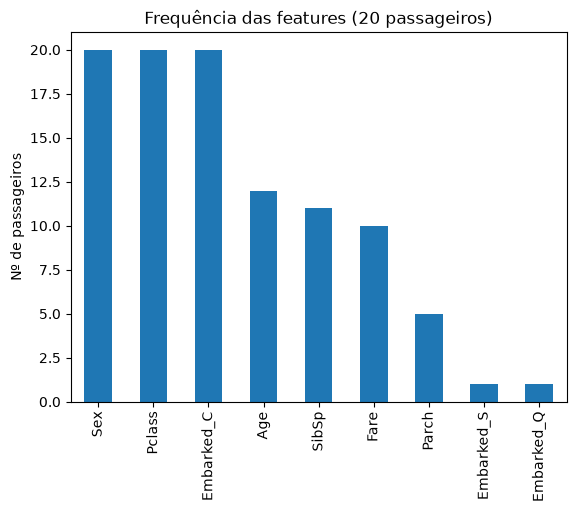

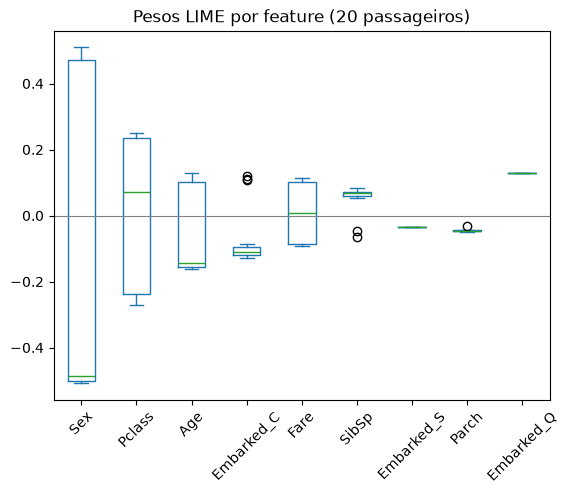

In [14]:
import matplotlib.pyplot as plt

summary['Aparece'].plot.bar(title='Frequência das features (20 passageiros)')
plt.ylabel('Nº de passageiros'); plt.show()

weights_20.plot.box(rot=45, title='Pesos LIME por feature (20 passageiros)')
plt.axhline(0, color='grey', lw=0.8); plt.show()

# 2 · Fidelida

In [15]:
t0 = time.time()
exps_all, rows_all = zip(*[explain_passenger(i) for i in range(len(x_test))])
table_all = pd.DataFrame(rows_all)
print(f'{len(table_all)} passageiros em {time.time() - t0:.0f}s')

209 passageiros em 22s


In [16]:
fid = table_all[['Passenger', 'Real', 'P(Survived)', 'Local prediction', 'R2']].copy()
fid['|P - local_pred|'] = (fid['P(Survived)'] - fid['Local prediction']).abs().round(3)
fid['Confiança'] = pd.cut((fid['P(Survived)'] - 0.5).abs(), bins=[0, 0.2, 0.4, 0.5],
                          labels=['indeciso (0.3–0.7)', 'médio', 'confiante (<0.1 ou >0.9)'],
                          include_lowest=True)

display(fid.groupby('Confiança')[['R2', '|P - local_pred|']].agg(['mean', 'count']).round(3))
display(fid.sort_values('R2').head())                      # 5 com pior R²
display(fid.sort_values('|P - local_pred|', ascending=False).head())  # 5 com pior erro local

R2       |P - local_pred|      
                           mean count             mean count
Confiança                                                   
indeciso (0.3–0.7)        0.434    29            0.223    29
médio                     0.429    29            0.248    29
confiante (<0.1 ou >0.9)  0.438   151            0.230   151

,Passenger,Real,P(Survived),Local prediction,R2,|P - local_pred|,Confiança
35,444,0,0.002,0.321,0.356,0.319,confiante (<0.1 ou >0.9)
60,486,0,0.659,0.292,0.359,0.367,indeciso (0.3–0.7)
73,424,0,0.022,0.266,0.361,0.244,confiante (<0.1 ou >0.9)
24,507,0,0.015,0.257,0.362,0.242,confiante (<0.1 ou >0.9)
112,368,0,0.001,0.139,0.363,0.138,confiante (<0.1 ou >0.9)


,Passenger,Real,P(Survived),Local prediction,R2,|P - local_pred|,Confiança
25,262,0,0.983,0.224,0.438,0.759,confiante (<0.1 ou >0.9)
197,378,0,0.914,0.157,0.389,0.757,confiante (<0.1 ou >0.9)
65,972,0,0.821,0.081,0.451,0.740,médio
0,359,1,1.000,0.266,0.363,0.734,confiante (<0.1 ou >0.9)
74,148,0,0.958,0.229,0.460,0.729,confiante (<0.1 ou >0.9)


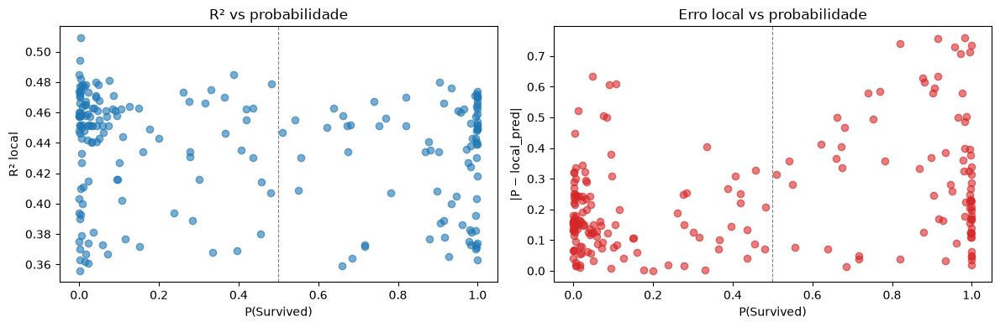

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fid['P(Survived)'], fid['R2'], alpha=0.6)
axes[0].set(xlabel='P(Survived)', ylabel='R² local', title='R² vs probabilidade')
axes[1].scatter(fid['P(Survived)'], fid['|P - local_pred|'], alpha=0.6, color='tab:red')
axes[1].set(xlabel='P(Survived)', ylabel='|P − local_pred|', title='Erro local vs probabilidade')
for ax in axes:
    ax.axvline(0.5, color='grey', ls='--', lw=0.8)
plt.tight_layout(); plt.savefig('ponto2_fidelidade.png', dpi=150); plt.show()

In [18]:
i_worst = fid['|P - local_pred|'].idxmax()
display(fid.loc[[i_worst]])
print(passenger_values(fid.loc[i_worst, 'Passenger']))
show_lime(exps_all[i_worst])

,Passenger,Real,P(Survived),Local prediction,R2,|P - local_pred|,Confiança
25,262,0,0.983,0.224,0.438,0.759,confiante (<0.1 ou >0.9)


Sex=M  Age=50  Pclass=1  Fare=55.9
SibSp=1  Parch=0  Embarked=S


# 3 · Estabilidade

In [19]:
i_p = 0
x = x_test.iloc[i_p].astype(float).values
print(passenger_values(x_test.index[i_p]))

records, times = [], {}
for n in [500, 1000, 5000]:
    t0 = time.time()
    for seed in range(10):
        exp = make_explainer(seed=seed).explain_instance(x, predict_fn, num_features=5, num_samples=n)
        for f, w in exp.as_map()[1]:
            records.append({'num_samples': n, 'seed': seed, 'feature': feature_names[f], 'weight': w})
    times[n] = (time.time() - t0) / 10   # tempo médio por explicação

stab = pd.DataFrame(records)

Sex=M  Age=1  Pclass=2  Fare=29.0
SibSp=0  Parch=2  Embarked=S


In [20]:
stab_sum = stab.groupby(['num_samples', 'feature'])['weight'].agg(
    vezes='count', peso_medio='mean', minimo='min', maximo='max', std='std')
stab_sum['amplitude'] = stab_sum['maximo'] - stab_sum['minimo']
stab_sum['muda_sinal'] = (stab_sum['minimo'] < 0) & (stab_sum['maximo'] > 0)
display(stab_sum.round(3))

vezes  peso_medio  minimo  maximo    std  amplitude  \
num_samples feature                                                           
500         Age             9       0.140   0.094   0.191  0.033      0.097   
            Embarked_C      7      -0.135  -0.208  -0.064  0.044      0.144   
            Embarked_Q      1       0.173   0.173   0.173    NaN      0.000   
            Fare            7      -0.087  -0.099  -0.070  0.010      0.029   
            Parch           4       0.112   0.080   0.135  0.023      0.055   
            Pclass          9       0.096   0.058   0.142  0.026      0.084   
            Sex            10      -0.459  -0.519  -0.410  0.029      0.109   
            SibSp           3       0.081   0.069   0.089  0.011      0.021   
1000        Age            10       0.139   0.080   0.188  0.030      0.108   
            Embarked_C      9      -0.110  -0.155  -0.067  0.030      0.088   
            Embarked_Q      1       0.167   0.167   0.167    NaN      0.000   
            Fare            6      -0.087  -0.106  -0.059  0.018      0.047   
            Parch           2       0.114   0.105   0.123  0.013      0.019   
            Pclass         10       0.096   0.067   0.133  0.019      0.066   
            Sex            10      -0.485  -0.506  -0.451  0.019      0.055   
            SibSp           2       0.070   0.070   0.070  0.000      0.000   
5000        Age            10       0.131   0.120   0.147  0.009      0.027   
            Embarked_C     10      -0.115  -0.128  -0.091  0.012      0.037   
            Fare            9      -0.088  -0.095  -0.076  0.007      0.019   
            Pclass          8       0.086   0.067   0.103  0.011      0.037   
            Sex            10      -0.491  -0.507  -0.472  0.012      0.036   
            SibSp           3       0.076   0.074   0.078  0.002      0.004   

                        muda_sinal  
num_samples feature                 
500         Age              False  
            Embarked_C       False  
            Embarked_Q       False  
            Fare             False  
            Parch            False  
            Pclass           False  
            Sex              False  
            SibSp            False  
1000        Age              False  
            Embarked_C       False  
            Embarked_Q       False  
            Fare             False  
            Parch            False  
            Pclass           False  
            Sex              False  
            SibSp            False  
5000        Age              False  
            Embarked_C       False  
            Fare             False  
            Pclass           False  
            Sex              False  
            SibSp            False

In [21]:
compact = pd.DataFrame({
    n: {
        'Features (vezes)': ', '.join(f'{f}({v})' for f, v in g['vezes'].sort_values(ascending=False).items()),
        'Peso médio |w|': g['peso_medio'].abs().mean().round(3),
        'Amplitude média': g['amplitude'].mean().round(3),
        'Tempo/explicação (s)': round(times[n], 3),
    }
    for n, g in stab_sum.reset_index(level=0, drop=True).groupby(stab_sum.index.get_level_values(0))
}).T
display(compact)

,Features (vezes),Peso médio |w|,Amplitude média,Tempo/explicação (s)
500,"Sex(10), Age(9), Pclass(9), Embarked_C(7), Fare(7), Parch(4), SibSp(3), Embarked_Q(1)",0.16,0.067,0.084
1000,"Age(10), Pclass(10), Sex(10), Embarked_C(9), Fare(6), Parch(2), SibSp(2), Embarked_Q(1)",0.159,0.048,0.09
5000,"Age(10), Embarked_C(10), Sex(10), Fare(9), Pclass(8), SibSp(3)",0.164,0.026,0.108


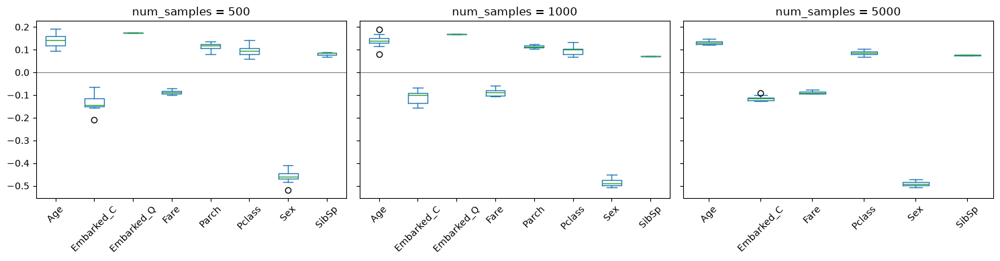

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, n in zip(axes, [500, 1000, 5000]):
    d = stab[stab['num_samples'] == n].pivot(index='seed', columns='feature', values='weight')
    d.plot.box(ax=ax, rot=45, title=f'num_samples = {n}')
    ax.axhline(0, color='grey', lw=0.8)
plt.tight_layout(); plt.savefig('ponto3_estabilidade.png', dpi=150); plt.show()

In [23]:
expl_disc = make_explainer(discretize=True)
expl_cont = make_explainer(discretize=False)
nf = len(feature_names)

exp_disc = expl_disc.explain_instance(x, predict_fn, num_features=nf)
exp_cont = expl_cont.explain_instance(x, predict_fn, num_features=nf)

show_lime(exp_disc)
show_lime(exp_cont)

# 4 · Change the representation


In [24]:
z = (x - expl_cont.scaler.mean_) / expl_cont.scaler.scale_
disc = {feature_names[f]: (cond, w) for (cond, w), (f, _) in zip(exp_disc.as_list(), exp_disc.as_map()[1])}

comp = pd.DataFrame([{
    'Feature': feature_names[f],
    'Valor': x[f],
    'Condição (True)': disc[feature_names[f]][0],
    'Peso (True)': disc[feature_names[f]][1],
    'Coef. (False)': w,
    'z': z[f],
    'Efeito = coef × z': w * z[f],
} for f, w in exp_cont.as_map()[1]]).round(3)
comp['Sinal da barra = sinal do efeito?'] = np.sign(comp['Coef. (False)']) == np.sign(comp['Efeito = coef × z'])
display(comp)

print('True : local_pred =', round(exp_disc.local_pred[0], 3), ' R² =', round(exp_disc.score, 3))
print('False: local_pred =', round(exp_cont.local_pred[0], 3), ' R² =', round(exp_cont.score, 3))

,Feature,Valor,Condição (True),Peso (True),Coef. (False),z,Efeito = coef × z,Sinal da barra = sinal do efeito?
0,Sex,1.000,0.00 < Sex <= 1.00,-0.494,-0.192,0.787,-0.151,True
1,Pclass,2.000,1.00 < Pclass <= 2.00,0.092,-0.125,-0.278,0.035,False
2,Age,0.833,Age <= 21.00,0.132,-0.058,-2.017,0.116,False
3,Fare,29.000,15.02 < Fare <= 34.38,-0.084,-0.024,-0.135,0.003,False
4,SibSp,0.000,SibSp <= 0.00,0.061,-0.005,-0.566,0.003,False
5,Embarked_C,0.000,Embarked_C <= 0.00,-0.108,0.005,-0.513,-0.003,False
6,Parch,2.000,Parch > 1.00,-0.001,0.005,1.877,0.009,True
7,Embarked_S,1.000,0.00 < Embarked_S <= 1.00,-0.028,-0.002,0.591,-0.001,True
8,Embarked_Q,0.000,Embarked_Q <= 0.00,0.080,-0.000,-0.230,0.000,True


True : local_pred = 0.3  R² = 0.404
False: local_pred = 0.765  R² = 0.347


# 5 · SP-LIME

In [25]:
def run_sp(n_exps, seed=123, data=x_test):
    sp = submodular_pick.SubmodularPick(make_explainer(seed=seed), data.astype(float).values, predict_fn,
                                        method='full', num_features=5, num_exps_desired=n_exps)
    rows = []
    for k, (i, exp) in enumerate(zip(sp.V, sp.sp_explanations)):
        pid, label = data.index[i], exp.available_labels()[0]
        rows.append({
            'Ordem': k + 1,
            'Passenger': pid,
            'Real': y_test.loc[pid],
            'P(Survived)': round(predict_fn(data.loc[[pid]].astype(float).values)[0, 1], 3),
            'Classe explicada': ['Did not Survive', 'Survived'][label],
            'Valores': passenger_values(pid).replace('\n', '  '),
            'Condições (pesos)': '; '.join(f'{c} ({w:+.3f})' for c, w in exp.as_list(label=label)),
        })
    return sp, pd.DataFrame(rows)

In [26]:
t0 = time.time()
sp3, sel3 = run_sp(3)
sp5, sel5 = run_sp(5)
sp5b, sel5b = run_sp(5, seed=7)
print(f'{time.time() - t0:.0f}s')

display(sel3); display(sel5); display(sel5b)
print('Mesmos passageiros com outra seed?', set(sel5['Passenger']) == set(sel5b['Passenger']))

66s


,Ordem,Passenger,Real,P(Survived),Classe explicada,Valores,Condições (pesos)
0,1,1084,0,0.017,Did not Survive,Sex=M Age=42 Pclass=3 Fare=8.4 SibSp=0 Parch=1 Embarked=S,0.00 < Sex <= 1.00 (+0.485); 2.00 < Pclass <= 3.00 (+0.242); Age > 38.00 (+0.146); Embarked_C <= 0.00 (+0.118); SibSp <= 0.00 (-0.069)
1,2,513,1,0.961,Survived,Sex=F Age=14 Pclass=2 Fare=30.1 SibSp=1 Parch=0 Embarked=C,Sex <= 0.00 (+0.502); Embarked_C > 0.00 (+0.116); Age <= 21.00 (+0.110); 15.02 < Fare <= 34.38 (-0.088); 1.00 < Pclass <= 2.00 (+0.087)
2,3,60,0,0.277,Did not Survive,Sex=M Age=36 Pclass=1 Fare=78.8 SibSp=1 Parch=0 Embarked=S,0.00 < Sex <= 1.00 (+0.481); Pclass <= 1.00 (-0.253); Embarked_C <= 0.00 (+0.116); Embarked_Q <= 0.00 (-0.095); 0.00 < SibSp <= 1.00 (+0.061)


,Ordem,Passenger,Real,P(Survived),Classe explicada,Valores,Condições (pesos)
0,1,1084,0,0.017,Did not Survive,Sex=M Age=42 Pclass=3 Fare=8.4 SibSp=0 Parch=1 Embarked=S,0.00 < Sex <= 1.00 (+0.485); 2.00 < Pclass <= 3.00 (+0.242); Age > 38.00 (+0.146); Embarked_C <= 0.00 (+0.118); SibSp <= 0.00 (-0.069)
1,2,513,1,0.961,Survived,Sex=F Age=14 Pclass=2 Fare=30.1 SibSp=1 Parch=0 Embarked=C,Sex <= 0.00 (+0.502); Embarked_C > 0.00 (+0.116); Age <= 21.00 (+0.110); 15.02 < Fare <= 34.38 (-0.088); 1.00 < Pclass <= 2.00 (+0.087)
2,3,60,0,0.277,Did not Survive,Sex=M Age=36 Pclass=1 Fare=78.8 SibSp=1 Parch=0 Embarked=S,0.00 < Sex <= 1.00 (+0.481); Pclass <= 1.00 (-0.253); Embarked_C <= 0.00 (+0.116); Embarked_Q <= 0.00 (-0.095); 0.00 < SibSp <= 1.00 (+0.061)
3,4,912,0,0.002,Did not Survive,Sex=M Age=30 Pclass=3 Fare=7.9 SibSp=0 Parch=0 Embarked=S,0.00 < Sex <= 1.00 (+0.488); 2.00 < Pclass <= 3.00 (+0.232); Embarked_C <= 0.00 (+0.135); Fare <= 8.05 (-0.105); SibSp <= 0.00 (-0.060)
4,5,228,0,0.869,Survived,Sex=M Age=18 Pclass=1 Fare=108.9 SibSp=1 Parch=0 Embarked=C,0.00 < Sex <= 1.00 (-0.481); Pclass <= 1.00 (+0.243); Age <= 21.00 (+0.154); Embarked_C > 0.00 (+0.131); Parch <= 0.00 (-0.058)


,Ordem,Passenger,Real,P(Survived),Classe explicada,Valores,Condições (pesos)
0,1,1084,0,0.017,Did not Survive,Sex=M Age=42 Pclass=3 Fare=8.4 SibSp=0 Parch=1 Embarked=S,0.00 < Sex <= 1.00 (+0.472); 2.00 < Pclass <= 3.00 (+0.258); Age > 38.00 (+0.161); Embarked_C <= 0.00 (+0.114); SibSp <= 0.00 (-0.067)
1,2,513,1,0.961,Survived,Sex=F Age=14 Pclass=2 Fare=30.1 SibSp=1 Parch=0 Embarked=C,Sex <= 0.00 (+0.487); Age <= 21.00 (+0.132); 1.00 < Pclass <= 2.00 (+0.097); Embarked_C > 0.00 (+0.095); 15.02 < Fare <= 34.38 (-0.083)
2,3,60,0,0.277,Did not Survive,Sex=M Age=36 Pclass=1 Fare=78.8 SibSp=1 Parch=0 Embarked=S,0.00 < Sex <= 1.00 (+0.505); Pclass <= 1.00 (-0.236); Embarked_Q <= 0.00 (-0.126); Embarked_C <= 0.00 (+0.107); 0.00 < SibSp <= 1.00 (+0.045)
3,4,837,0,0.001,Did not Survive,Sex=M Age=37 Pclass=3 Fare=7.9 SibSp=2 Parch=0 Embarked=S,0.00 < Sex <= 1.00 (+0.504); 2.00 < Pclass <= 3.00 (+0.225); Embarked_C <= 0.00 (+0.108); Fare <= 8.05 (-0.089); Parch <= 0.00 (+0.055)
4,5,494,1,1.000,Survived,Sex=F Age=24 Pclass=2 Fare=37.0 SibSp=1 Parch=1 Embarked=C,Sex <= 0.00 (+0.498); Embarked_C > 0.00 (+0.125); 1.00 < Pclass <= 2.00 (+0.102); 0.00 < SibSp <= 1.00 (-0.052); Fare > 34.38 (-0.040)


Mesmos passageiros com outra seed? False


In [27]:
def coverage(sp):
    imp = {}
    for exp in sp.explanations:                      # todos os candidatos = visão "global"
        lab = exp.available_labels()[0]
        for f, w in exp.as_map()[lab]:
            imp[feature_names[f]] = imp.get(feature_names[f], 0) + abs(w)
    covered = {feature_names[f] for exp in sp.sp_explanations
               for f, _ in exp.as_map()[exp.available_labels()[0]]}
    t = pd.Series(imp).sort_values(ascending=False).round(2).to_frame('Importância global Σ|w|')
    t['Coberta pelo SP?'] = t.index.isin(covered)
    return t

display(coverage(sp5))

,Importância global Σ|w|,Coberta pelo SP?
Sex,102.31,True
Pclass,42.29,True
Embarked_C,23.05,True
Age,15.15,True
Fare,11.61,True
SibSp,8.42,True
Embarked_Q,2.30,True
Parch,1.31,True
Embarked_S,0.12,False


In [29]:
sel = sel5['Passenger']
rep = pd.DataFrame({
    'Teste (média)': x_test.astype(float).mean(),
    'SP-LIME (média)': x_test.loc[sel].astype(float).mean(),
}).round(2)
rep.loc['Survived (real)'] = [y_test.mean().round(2), y_test.loc[sel].mean().round(2)]
display(rep)

for exp, (_, row) in zip(sp5.sp_explanations, sel5.iterrows()):
    display(HTML(f"<h4>Passageiro {row['Passenger']} — real: {row['Real']} | "
                 f"P(Survived) = {row['P(Survived)']} | classe explicada: {row['Classe explicada']}</h4>"))
    show_lime(exp)

,Teste (média),SP-LIME (média)
Pclass,2.11,2.00
Sex,0.68,0.80
Age,29.83,28.00
SibSp,0.44,0.60
Parch,0.41,0.20
Fare,35.63,46.82
Embarked_C,0.18,0.40
Embarked_Q,0.04,0.00
Embarked_S,0.78,0.60
Survived (real),0.43,0.20


# 6 Extra

,R2,erro_local
kernel_width,,
0.5,0.333,0.196
1.0,0.432,0.227
2.0,0.436,0.229
3.0,0.436,0.229
5.0,0.436,0.229


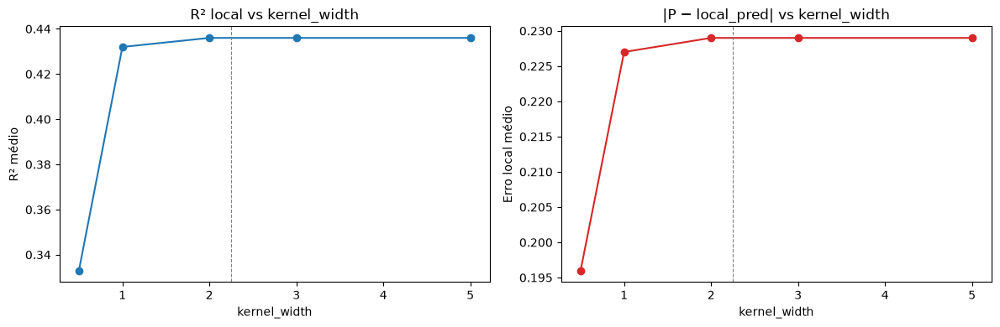

In [31]:
res = []
for kw in [0.5, 1, 2, 3, 5]:
    expl = make_explainer(kernel_width=kw)
    for i in range(50):
        x_i = x_test.iloc[i].astype(float).values
        e = expl.explain_instance(x_i, predict_fn, num_features=5)
        p = predict_fn(x_i.reshape(1, -1))[0, 1]
        res.append({'kernel_width': kw, 'R2': e.score, 'erro_local': abs(p - e.local_pred[0])})

kw_res = pd.DataFrame(res).groupby('kernel_width').mean().round(3)
display(kw_res)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
kw_res['R2'].plot(ax=axes[0], marker='o', title='R² local vs kernel_width')
axes[0].set_ylabel('R² médio')
kw_res['erro_local'].plot(ax=axes[1], marker='o', color='tab:red', title='|P − local_pred| vs kernel_width')
axes[1].set_ylabel('Erro local médio')
for ax in axes:
    ax.axvline(np.sqrt(len(feature_names)) * 0.75, color='grey', ls='--', lw=0.8)  # valor default
plt.tight_layout(); plt.savefig('ponto6_kernel_width.png', dpi=150); plt.show()

,LIME Σ|w|,XGBoost (gain)
Sex,0.496,0.494
Pclass,0.205,0.179
Embarked_C,0.111,0.053
Age,0.074,0.034
Fare,0.056,0.036
SibSp,0.041,0.085
Embarked_Q,0.012,0.042
Parch,0.005,0.046
Embarked_S,0.001,0.030


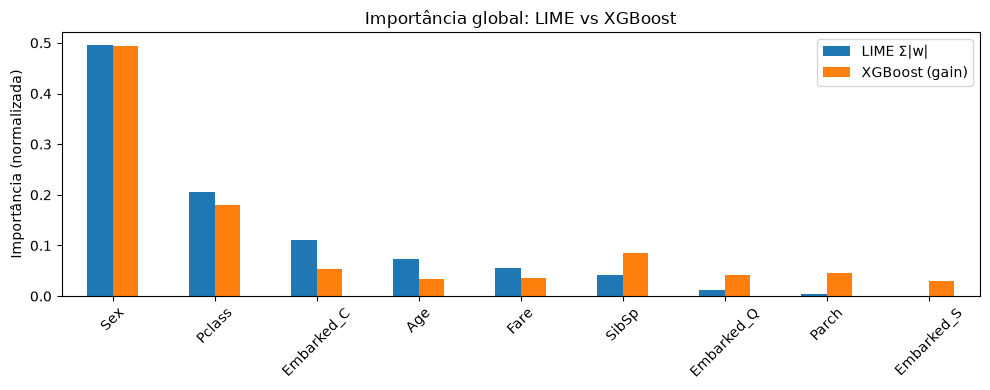

In [32]:
lime_imp = pd.Series(0.0, index=feature_names)
for e in exps_all:
    for f, w in e.as_map()[1]:
        lime_imp[feature_names[f]] += abs(w)

imp = pd.DataFrame({
    'LIME Σ|w|': lime_imp / lime_imp.sum(),
    'XGBoost (gain)': pd.Series(model.feature_importances_, index=feature_names),
}).round(3).sort_values('LIME Σ|w|', ascending=False)
display(imp)

imp.plot.bar(figsize=(10, 4), rot=45, title='Importância global: LIME vs XGBoost')
plt.ylabel('Importância (normalizada)')
plt.tight_layout(); plt.savefig('ponto6_importancia.png', dpi=150); plt.show()